In [1]:
#importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# If yfinance is missing, run this once in a terminal: pip install yfinance

In [3]:
import yfinance as yf
gold   = yf.download("GC=F",  start="2016-01-01", end="2026-11-06")
usdinr = yf.download("INR=X", start="2016-01-01", end="2026-11-06")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [4]:
#removing the half finished 5 November row
gold = gold.loc[:"2026-11-04"]

In [5]:
#Removing the extra heading row and rearrange the columns
gold.columns = gold.columns.get_level_values(0)
gold = gold[["Open", "High", "Low", "Close", "Volume"]]

In [6]:
#checking the datatype of the table where gold prices are stored
print(type(gold))

<class 'pandas.core.frame.DataFrame'>


In [7]:
#displaying first 10 rows of the table
gold.head(10)

Price,Open,High,Low,Close,Volume
Date,,,,,
2016-01-04,1063.400024,1082.500000,1063.199951,1075.099976,143
2016-01-05,1075.599976,1081.500000,1075.300049,1078.400024,82
2016-01-06,1081.599976,1093.699951,1081.599976,1091.900024,52
2016-01-07,1091.599976,1109.400024,1091.599976,1107.699951,122
2016-01-08,1111.099976,1111.099976,1093.000000,1097.800049,98
2016-01-11,1105.699951,1107.900024,1096.500000,1096.500000,43
2016-01-12,1093.800049,1098.500000,1084.000000,1085.599976,87
2016-01-13,1081.500000,1093.900024,1081.500000,1087.500000,50
2016-01-14,1091.500000,1091.500000,1073.699951,1073.900024,59


In [8]:
#displaying the last 10 rows of the table
gold.tail(10)

Price,Open,High,Low,Close,Volume
Date,,,,,
2026-10-22,4159.000000,4164.299805,4036.800049,4060.399902,214607
2026-10-23,4042.199951,4050.199951,3989.100098,4007.899902,180320
2026-10-26,4012.199951,4044.000000,3990.899902,4038.399902,126007
2026-10-27,4032.800049,4079.399902,4001.600098,4074.600098,139103
2026-10-28,4073.600098,4097.200195,4036.899902,4051.600098,151463
2026-10-29,4081.399902,4081.699951,4016.300049,4031.399902,142006
2026-10-30,4033.600098,4038.199951,3879.300049,3898.899902,237470
2026-11-02,3890.000000,3980.800049,3889.000000,3969.600098,172512
2026-11-03,3960.500000,3981.699951,3904.100098,3940.399902,163000


In [9]:
#checking the shape of the table
gold.shape

(2726, 5)

In [10]:
#saving the datasets as csv files
gold.to_csv("gold_usd.csv")
usdinr.to_csv("usdinr.csv")

In [11]:
#getting the datatypes of each column in the gold table
gold.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2726 entries, 2016-01-04 to 2026-11-04
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2726 non-null   float64
 1   High    2726 non-null   float64
 2   Low     2726 non-null   float64
 3   Close   2726 non-null   float64
 4   Volume  2726 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 127.8 KB


In [12]:
#describing and understanding the data using statistical tools
gold.describe()

Price,Open,High,Low,Close,Volume
count,2726.000000,2726.000000,2726.000000,2726.000000,2726.000000
mean,2046.133676,2062.135399,2029.762656,2046.353632,118952.725238
std,970.162268,985.178510,954.242189,970.215388,110729.180693
min,1063.400024,1081.500000,1063.199951,1073.900024,0.000000
25%,1311.599976,1316.049988,1309.299957,1312.324951,223.250000
50%,1794.250000,1806.350037,1782.049988,1794.299988,139161.000000
75%,2067.424927,2085.074951,2048.500000,2069.700012,199218.250000
max,5415.700195,5586.200195,5272.899902,5318.399902,570055.000000


In [13]:
#checking all the column names
gold.columns

Index(['Open', 'High', 'Low', 'Close', 'Volume'], dtype='object', name='Price')

In [14]:
#checking for empty cells
gold.isnull()

Price,Open,High,Low,Close,Volume
Date,,,,,
2016-01-04,False,False,False,False,False
2016-01-05,False,False,False,False,False
2016-01-06,False,False,False,False,False
2016-01-07,False,False,False,False,False
2016-01-08,False,False,False,False,False
...,...,...,...,...,...
2026-10-29,False,False,False,False,False
2026-10-30,False,False,False,False,False
2026-11-02,False,False,False,False,False


In [15]:
#checking the total number of empty cells
gold.isnull().sum()

Price
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

In [16]:
#checking for total number of duplicates in a data
gold.duplicated().sum()

np.int64(0)

In [17]:
# Find the lowest and highest closing prices
import math as m
a = round(gold["Close"].min(),2)
b = round(gold["Close"].max(),2)
print(f"Minimum closing value is = {a}")
print(f"Maximum closing value is = {b}")

Minimum closing value is = 1073.9
Maximum closing value is = 5318.4


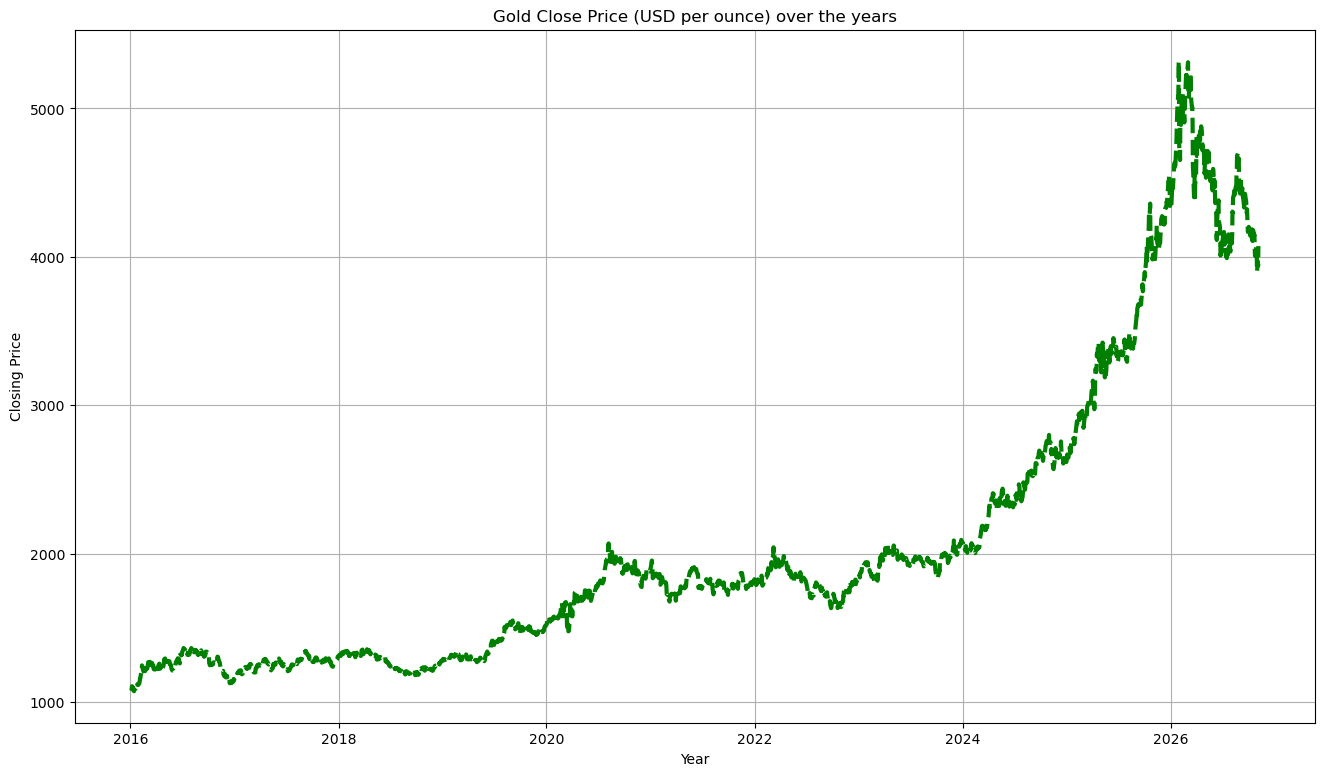

In [18]:
x = gold.index
y = gold["Close"]
plt.figure(figsize=(16,9))
plt.xlabel('Year')
plt.ylabel('Closing Price')
plt.title("Gold Close Price (USD per ounce) over the years")
plt.plot(x,y,color ="g",linestyle = "--",linewidth = 3)
plt.grid()
plt.show()

In [19]:
#reading the Dhanteras dates
df = pd.read_excel("dhanteras_dates.xlsx")
df

,S.No,Years,Dhanteras Dates,Day
0,1,2016,2016-10-28,Friday
1,2,2017,2017-10-17,Tuesday
2,3,2018,2018-11-05,Monday
3,4,2019,2019-10-25,Friday
4,5,2020,2020-11-13,Friday
5,6,2021,2021-11-02,Tuesday
6,7,2022,2022-10-22,Saturday
7,8,2023,2023-11-10,Friday
8,9,2024,2024-10-29,Tuesday
9,10,2025,2025-10-18,Saturday


In [20]:
#checking datatypes of the columns
df.dtypes

S.No                        int64
Years                       int64
Dhanteras Dates    datetime64[ns]
Day                        object
dtype: object

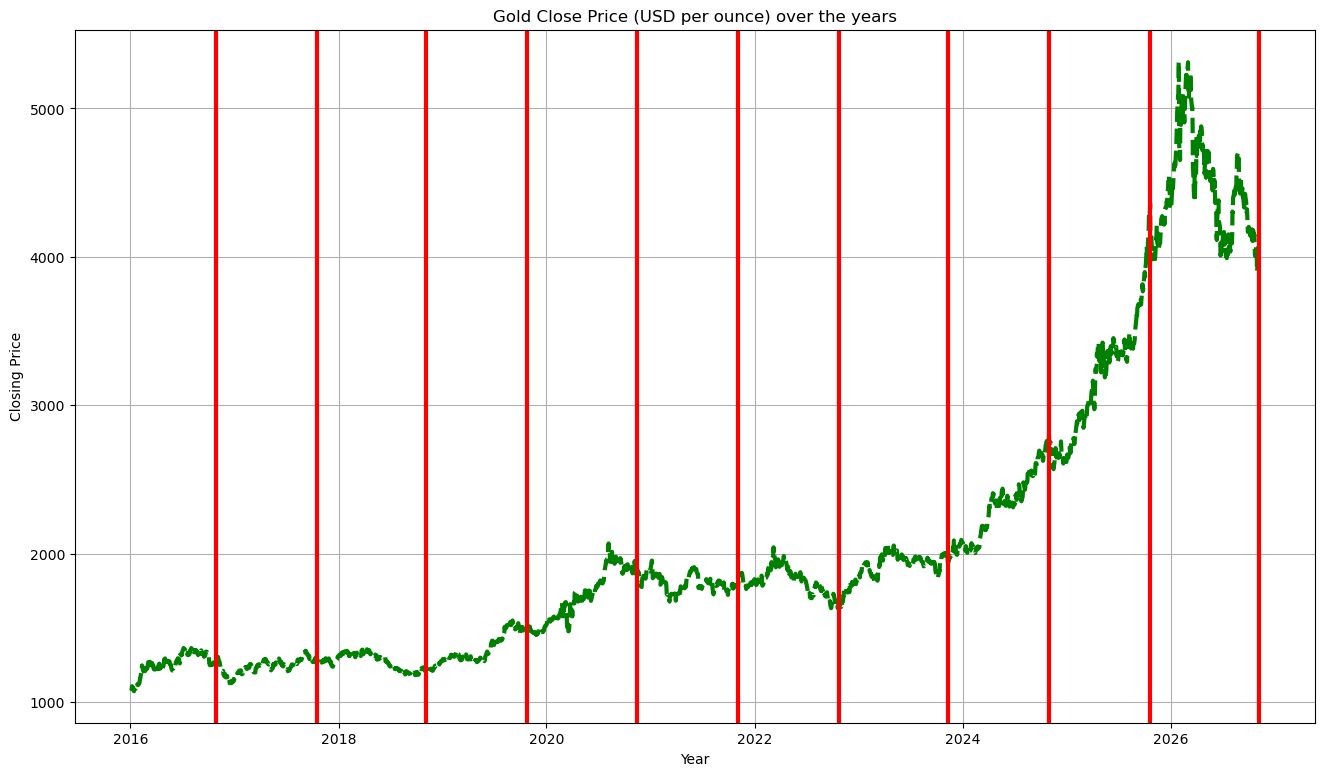

In [21]:
plt.figure(figsize=(16,9))
x = gold.index
y = gold["Close"]
plt.xlabel('Year')
plt.ylabel('Closing Price')
plt.title("Gold Close Price (USD per ounce) over the years")
plt.plot(x,y,color ="g",linestyle = "--",linewidth = 3)
for d in df["Dhanteras Dates"]:
    plt.axvline(d, color="r",linewidth=3)
plt.grid()
plt.show()

In [22]:
#taking out prices 7 days before and 7 days after Dhanteras
data = []
for date in df["Dhanteras Dates"]:
    start = date - pd.Timedelta(days=7)
    end = date + pd.Timedelta(days=7)
    selected = gold[
        (gold.index >= start) & (gold.index <= end)]
    data.append(selected)
    print(selected)

Price              Open         High          Low        Close  Volume
Date                                                                  
2016-10-21  1265.900024  1265.900024  1265.900024  1265.900024     224
2016-10-24  1269.199951  1269.199951  1261.800049  1262.000000      42
2016-10-25  1264.099976  1274.099976  1264.099976  1271.900024      61
2016-10-26  1274.000000  1274.000000  1264.800049  1264.800049     279
2016-10-27  1269.400024  1269.400024  1267.900024  1267.900024     338
2016-10-28  1270.300049  1281.500000  1262.000000  1275.500000     560
2016-10-31  1276.599976  1276.599976  1271.500000  1271.500000      58
2016-11-01  1279.300049  1290.699951  1279.000000  1286.400024      49
2016-11-02  1288.300049  1307.000000  1288.300049  1306.800049      30
2016-11-03  1296.400024  1303.099976  1287.300049  1302.099976      73
2016-11-04  1300.000000  1303.300049  1296.699951  1303.300049      11
Price              Open         High          Low        Close  Volume
Date  

In [23]:
#For each Dhanteras (2016 to 2025), find the gold price 7 trading days before, on the day, and 7 trading days after, then work out the % change before and after
result = []

for d in df["Dhanteras Dates"]:
    if d.year < 2026:
        prices = gold.loc[d:, "Close"]
        first_day = prices.index[0]
        before = gold.loc[:first_day, "Close"]
        result.append([
            d.year,
            before.iloc[-8],
            prices.iloc[0],
            prices.iloc[7]])

result = pd.DataFrame(result, columns=["Year", "Price Before 7 Days", "Dhanteras Price", "Price After 7 Days"])

result["Change Before %"] = ((result["Dhanteras Price"] - result["Price Before 7 Days"])/ result["Price Before 7 Days"] * 100)

result["Change After %"] = ((result["Price After 7 Days"] - result["Dhanteras Price"])/ result["Dhanteras Price"] * 100)

result

,Year,Price Before 7 Days,Dhanteras Price,Price After 7 Days,Change Before %,Change After %
0,2016,1267.900024,1275.500000,1273.400024,0.599414,-0.164639
1,2017,1271.599976,1283.000000,1266.300049,0.896510,-1.301633
2,2018,1229.099976,1229.800049,1207.900024,0.056958,-1.780779
3,2019,1488.000000,1499.500000,1480.800049,0.772849,-1.247079
4,2020,1896.199951,1886.199951,1804.599976,-0.527371,-4.326157
5,2021,1796.300049,1789.400024,1863.900024,-0.384124,4.163407
6,2022,1677.000000,1654.099976,1650.000000,-1.365535,-0.247867
7,2023,1987.500000,1937.699951,2001.599976,-2.505663,3.297725
8,2024,2730.000000,2781.100098,2705.800049,1.871798,-2.707563
9,2025,3972.600098,4359.399902,4000.699951,9.736691,-8.228196


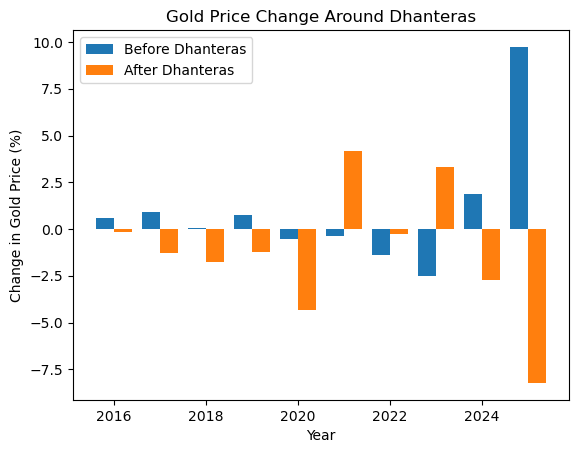

In [24]:
plt.bar(result["Year"]- 0.2, result["Change Before %"],width=0.4, label="Before Dhanteras")
plt.bar(result["Year"]+ 0.2, result["Change After %"],width=0.4, label="After Dhanteras")
plt.xlabel("Year")
plt.ylabel("Change in Gold Price (%)")
plt.title("Gold Price Change Around Dhanteras")
plt.legend()
plt.show()

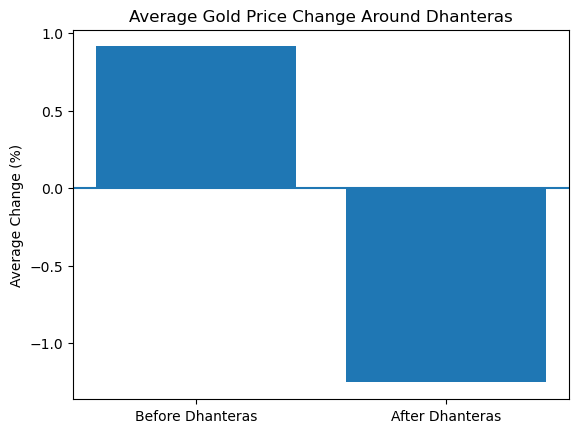

In [25]:
average = [result["Change Before %"].mean(),result["Change After %"].mean()]
plt.bar(["Before Dhanteras", "After Dhanteras"], average)
plt.ylabel("Average Change (%)")
plt.title("Average Gold Price Change Around Dhanteras")
plt.axhline(0)
plt.show()

In [26]:
#Remove 2025 from the table (it was an unusual year) and print the average % change before and after Dhanteras for the other years
without_2025 = result[result["Year"] != 2025]
print(without_2025["Change Before %"].mean())
print(without_2025["Change After %"].mean())

-0.0650179984977805
-0.4793985282392624


In [27]:
#Work out how much gold's price changes over any 7 trading days, then print the average change and the usual size of the change
normal = gold["Close"].pct_change(7) * 100
print(normal.mean())
print(normal.std())

0.3723177963876113
2.718040577248024


# Findings So Far
# Data Used
- Daily gold prices (Close) from January 2016 to 4 November 2026, in US dollars per ounce.
- These are international prices, so they will not match the rate a jeweller shows in India.
- Dhanteras 2026 is left out of the before/after comparison because the prices after it do not exist yet.
- "Before" and "after" mean 7 trading days (about one and a half weeks).

# 1. The long term trend
- From 2016 to 2019 gold was calm, between about 1,100 and 1,400.
- From 2019 to 2023 it moved up to about 2,000 and then stayed around there.
- From 2024 to early 2026 it climbed very fast to about 5,300.
- Since early 2026 it has fallen back to about 4,000.
- Gold has been much less stable since 2024 than before.

# 2. What happens after Dhanteras
- I looked at the price change in the 7 trading days after Dhanteras, for 2016 to 2025.
- The price went down in 8 years and up in only 2 (2021 and 2023).
- The changes ranged from about -8.2% to +4.2%.

# 3. My first guess was half right
- I guessed that gold fell after Dhanteras up to 2021 and rose after it from 2021 onwards.
- The first half was right: gold fell in the week after Dhanteras in every year from 2016 to 2020.
- The second half was wrong: it rose in 2021 and 2023, but fell in 2022, 2024 and 2025.

# 4. The 2025 surprise
- In 2025 gold rose about 9.7% in the 7 trading days before Dhanteras and fell about 8.2% in the 7 trading days after.
- No other year came close to that.
- With all years, the average is +0.92% before and -1.25% after. Without 2025 it is -0.07% before and -0.48% after.
- So 2025 explains most of the "up before" pattern, but the "down after" pattern stays even without it.

# 5. Is Dhanteras week special?
- In any normal 7-trading-day period, gold moves about 0.37% on average, and the usual size of a move is about 2.7% up or down.
- Gold falls in about 43% of ordinary weeks. After Dhanteras it fell in 8 of 10.
- In 4 of 10 years (2020, 2021, 2023, 2025) the move after Dhanteras was bigger than the usual size. In ordinary weeks this happens about 1 time in 4.
- The "before" weeks looked normal, except for 2025.

# Conclusion
- I found no clear pattern before Dhanteras.
- After Dhanteras gold fell in 8 of 10 years, which is more often than in ordinary weeks. But the falls were mostly small (about -0.5% on average without 2025), compared with a usual weekly move of 2.7%.
- I only have 10 years of data and I checked several patterns, so this could be luck. I would call it a mild tendency, not a rule.

In [28]:
#checking how much gold moves each day (in %), then find the usual size of these daily moves for each year
daily_change = gold["Close"].pct_change() * 100
yearly = daily_change.groupby(gold.index.year).std()
yearly

Date
2016    1.023568
2017    0.654624
2018    0.664167
2019    0.726414
2020    1.365841
2021    0.943458
2022    0.992678
2023    0.845528
2024    0.963995
2025    1.313519
2026    1.843927
Name: Close, dtype: float64

# Disclaimer
2026 is not a full year, because the data stops on 4 November.

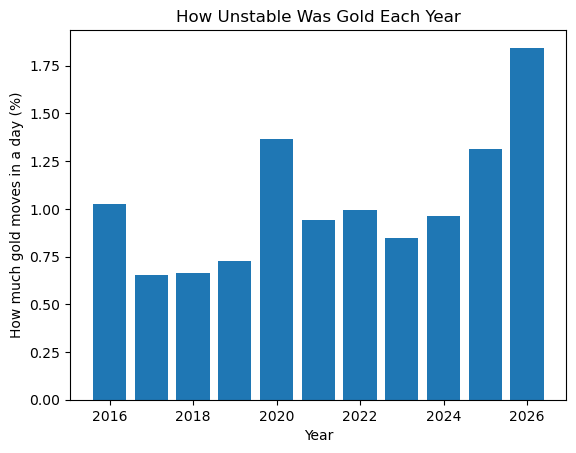

In [29]:
plt.bar(yearly.index, yearly.values)
plt.xlabel("Year")
plt.ylabel("How much gold moves in a day (%)")
plt.title("How Unstable Was Gold Each Year")
plt.show()

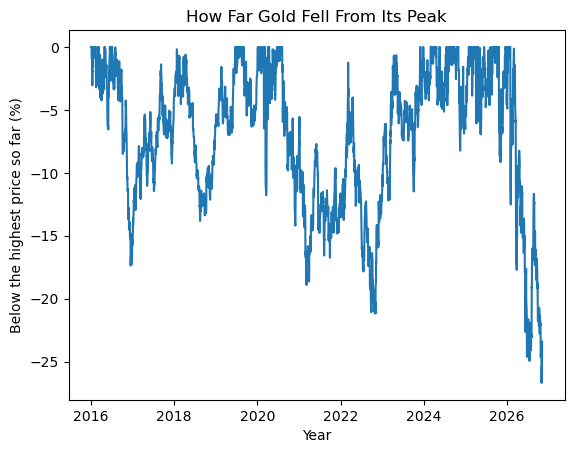

In [30]:
peak_so_far = gold["Close"].cummax()
fall_from_peak = (gold["Close"] - peak_so_far) / peak_so_far * 100
plt.plot(fall_from_peak.index, fall_from_peak.values)
plt.xlabel("Year")
plt.ylabel("Below the highest price so far (%)")
plt.title("How Far Gold Fell From Its Peak")
plt.show()

# 6. When was gold stable and when was it not?
- I measured how much gold's price moves on a typical day, year by year.
- The calmest years were 2017, 2018 and 2019, when gold moved about 0.65% to 0.75% a day.
- 2020 was jumpy (about 1.4% a day), and 2025 and 2026 were jumpy too.
- 2026 was the most unstable year, at about 1.8% a day, nearly three times as much as 2018. The 2026 figure covers only part of the year, up to 4 November.

# 7. Falls after peaks
- After each high, gold pulled back at some point. The falls from the highest price were about 17% (end of 2016), 19% (early 2021), 21% (late 2022), 12% (early 2023) and 9% (late 2025).
- The biggest fall came in 2026. Gold dropped about 27% from its early-2026 high of about 5,300 to a low of about 3,900 on 30 October.
- It has since recovered part of that fall.
- So gold usually pulls back after big rises, but only the 2026 fall was this large.